### Explainable Credit Risk Assessment

#### 1. Load the Data
- We will bring in the loan applicant data.
- This data has details like income, age, and loan amount.
- It also tells us who repaid and who defaulted.

In [236]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [190]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


#### 2. Exploratory Data Analysis (EDA)
- Here we simply look at the data before touching it.
- We want to understand it first, then work on it.
##### Basic info about the data
- Check how many rows and columns we have.
- Check the data type of each column.

In [191]:
df.shape

(32581, 12)

In [192]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


##### Missing values
- Find out which columns have empty or missing values.
- This tells us where we may need to fix things later.

In [193]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

#### Target balance
- Check how many people defaulted vs how many repaid.
- This tells us if our data is balanced or imbalanced.

In [194]:
display(df['loan_status'].value_counts().to_frame(name='Count'))

,Count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

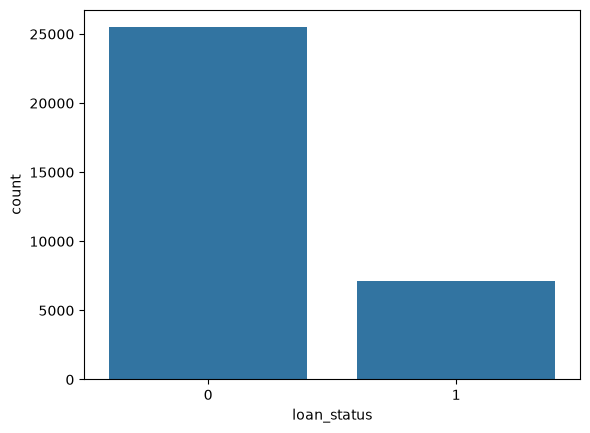

In [195]:
sns.countplot(x='loan_status',data=df)

#### Outlier check

- Look for values that seems to be impossible, like age 144.
- These are the signs of bad data entries

In [196]:
df.describe().T 

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


In [197]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
numerical_cols

['person_age',
 'person_income',
 'person_emp_length',
 'loan_amnt',
 'loan_int_rate',
 'loan_status',
 'loan_percent_income',
 'cb_person_cred_hist_length']

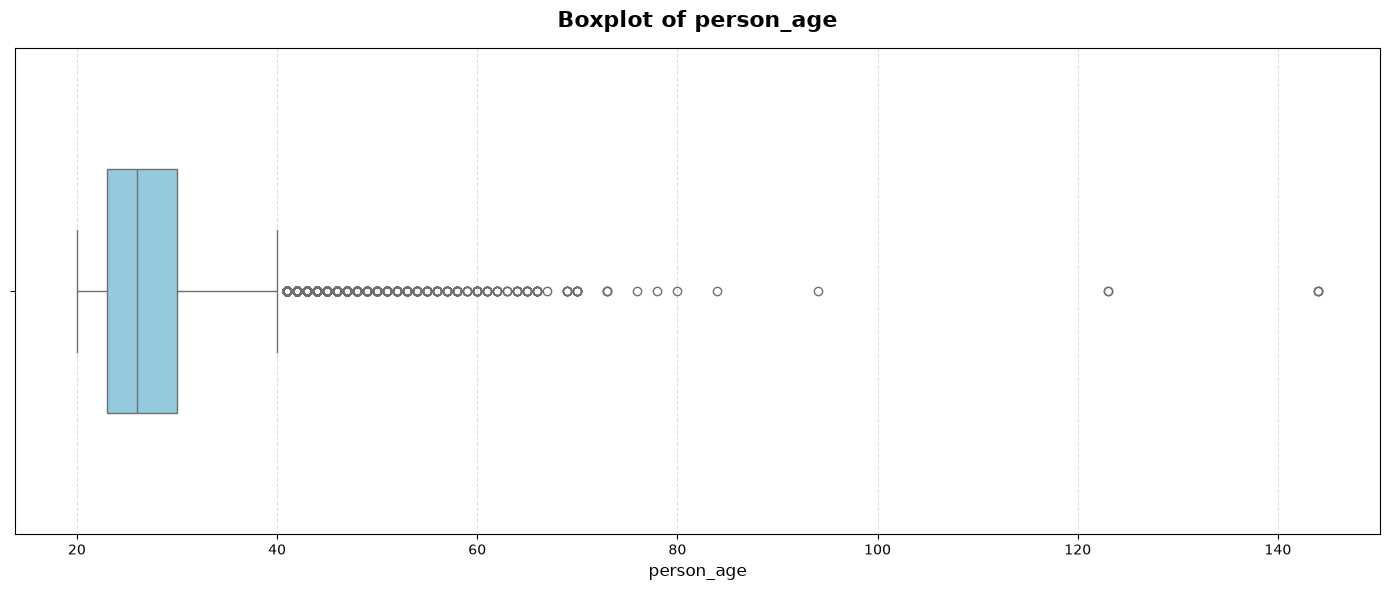

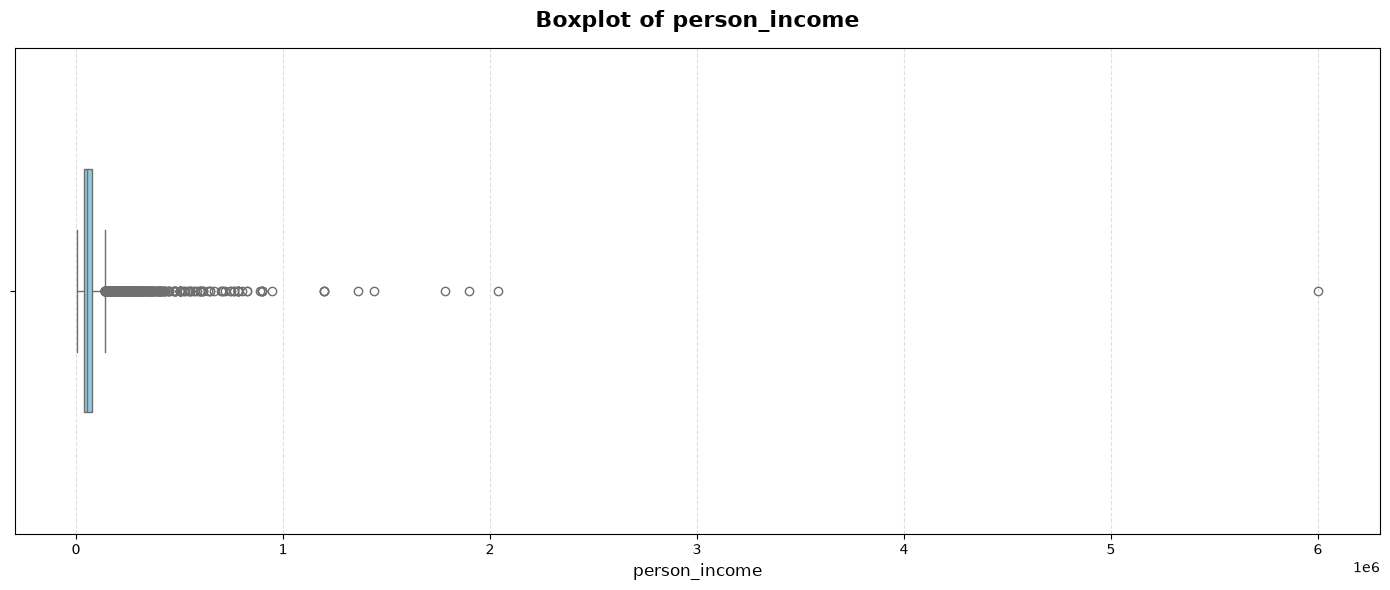

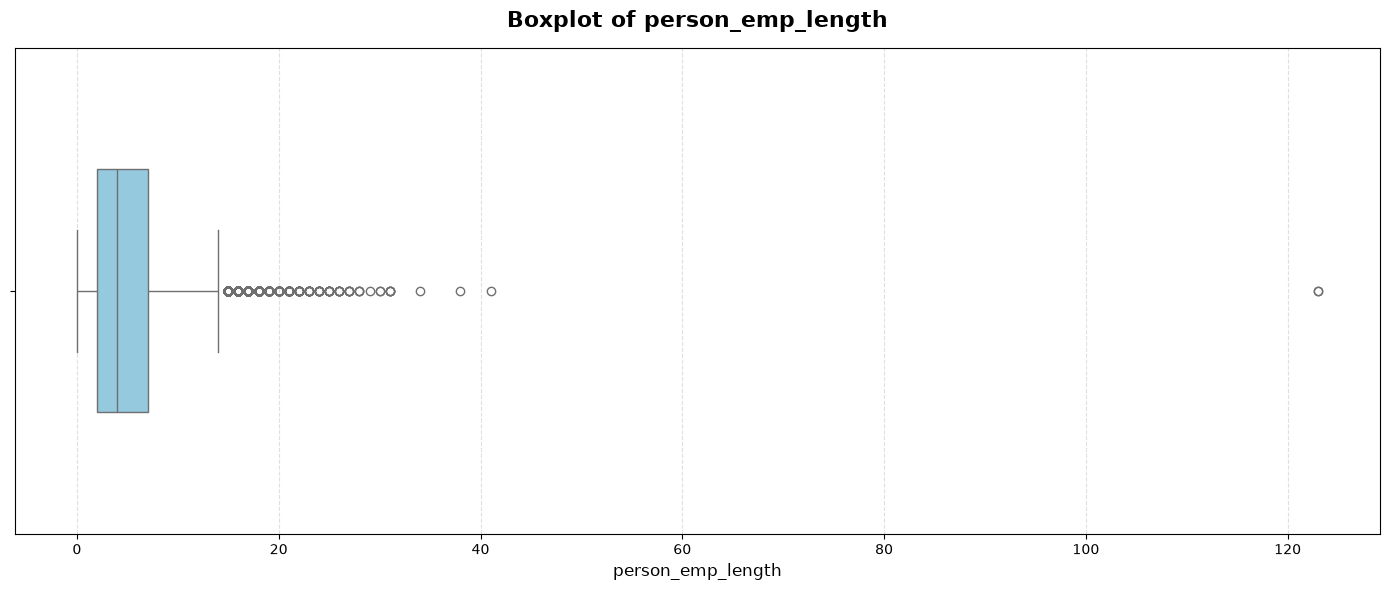

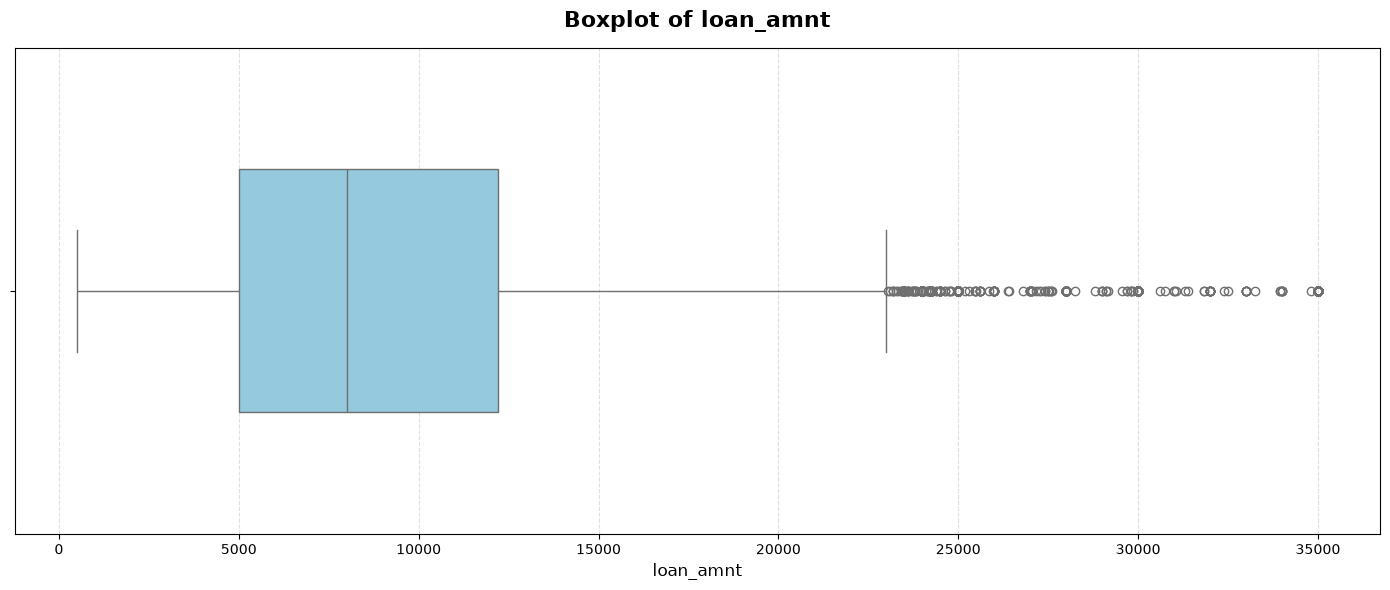

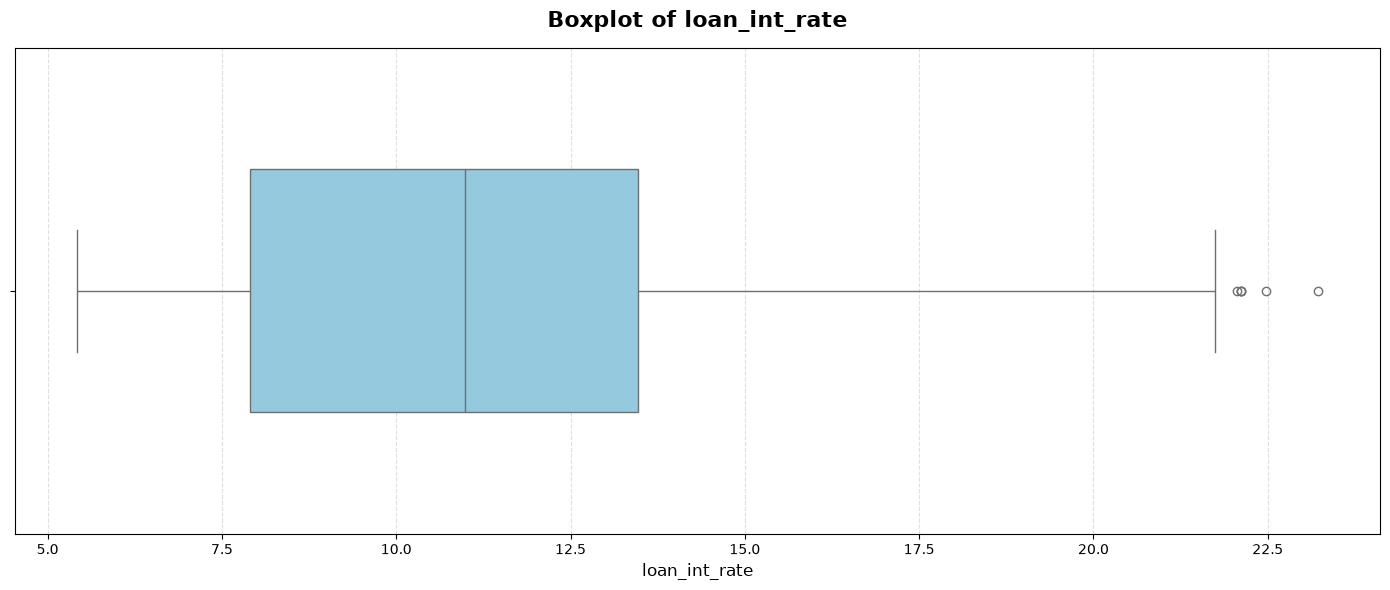

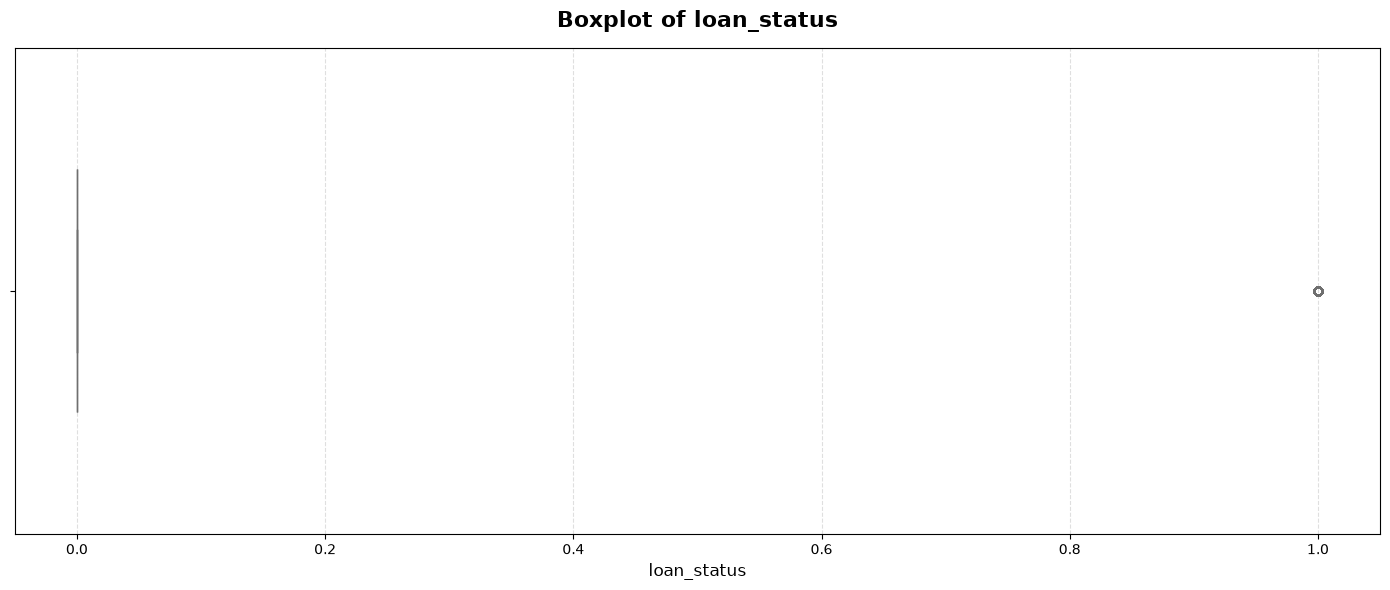

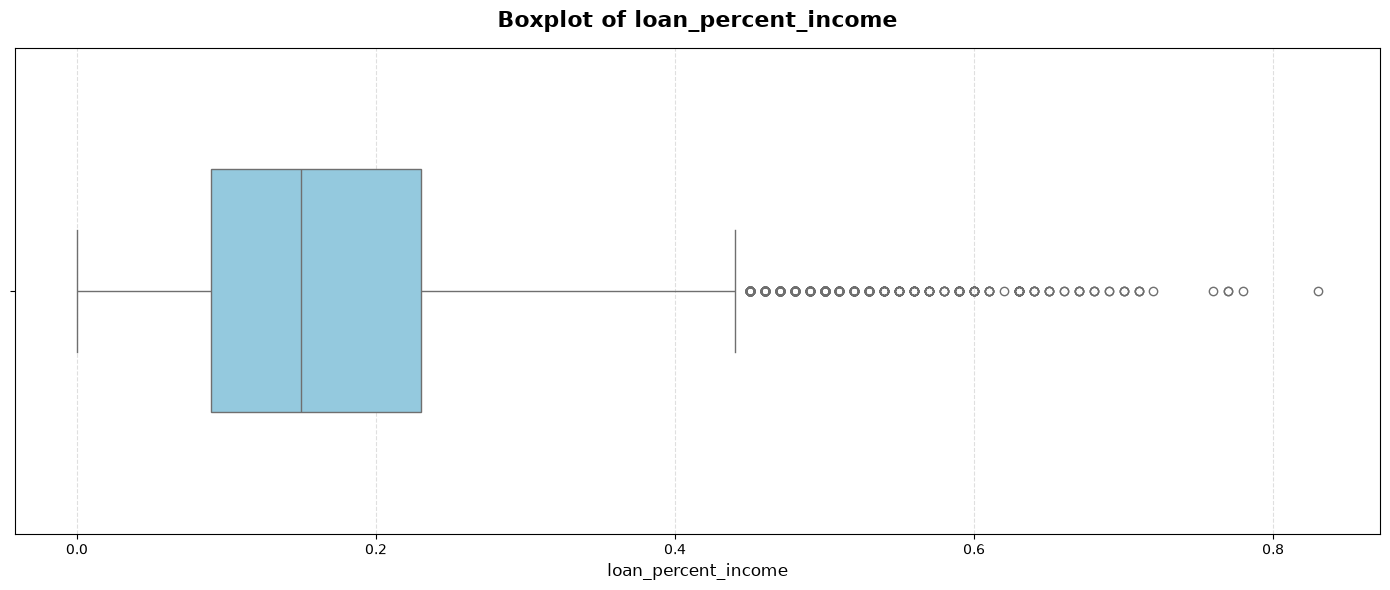

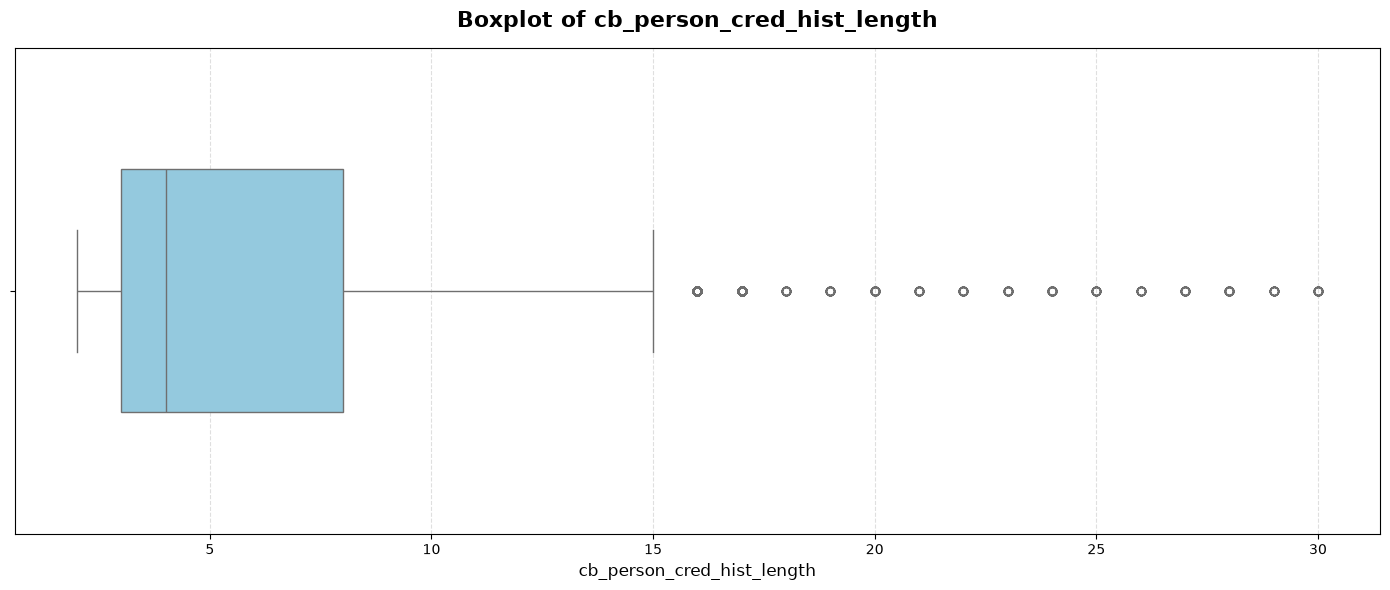

In [198]:
for col in numerical_cols:

    plt.figure(figsize=(14, 6))

    sns.boxplot(
        x=df[col],
        color="skyblue",
        width=0.5
    )

    plt.title(f"Boxplot of {col}", fontsize=16, fontweight="bold", pad=15)
    plt.xlabel(col, fontsize=12)
    plt.grid(axis="x", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

In [199]:
print("Outliers - Person age: ",(df['person_age']>100).sum())

print("\nOutliers - Person emp length: ",(df['person_emp_length']>60).sum())

Outliers - Person age:  5

Outliers - Person emp length:  2


#### Correlation check

- See how features are related to each other
- This helps us spot repeated or linked information, gives us a pattern

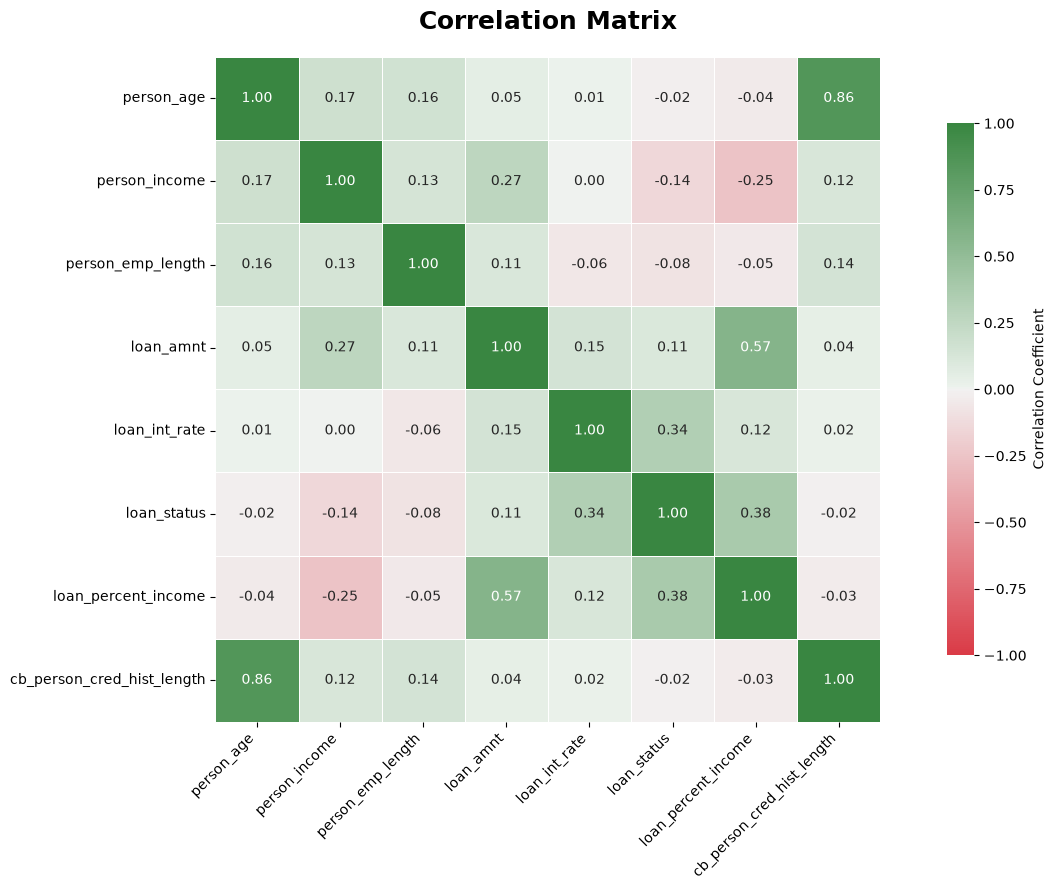

In [200]:
# Calculate correlation matrix
corr_matrix = df.corr(numeric_only=True)

# Set figure dimensions
plt.figure(figsize=(14, 9))

# Create custom colormap
cmap = sns.diverging_palette(10, 130, as_cmap=True)

# Plot heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap=cmap,
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar_kws={
        "shrink": 0.8,
        "label": "Correlation Coefficient"
    }
)

plt.title(
    "Correlation Matrix",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

#### 3. Data Validation & Outlier Handling

- Clean the data properly.
- Remove duplicate rows.
- Remove outliers ( with impossible values (impossible age or work experience)).
- Remove rows with zero or negative income and loan amount.
- Check if the interest rate looks realistic.
- Flag the observations(rows) where numbers don't add up correctly.

In [201]:
df_copy = df.copy(deep = True)

# Remove duplicate rows

print(f"Number of observations before removing the duplicates: {df_copy.shape[0]}")
df_copy = df_copy.drop_duplicates()
print(f"\nNumber of observations after removing the duplicates: {df_copy.shape[0]}")

Number of observations before removing the duplicates: 32581

Number of observations after removing the duplicates: 32416


In [202]:
# Removing/Handling outliers -- 18 < Age > 100 and Employment length > Person's age

print(f"Number of observations before handling the outliers: {df_copy.shape[0]}")

# Removing outliers from age
df_copy = df_copy[df_copy['person_age']>=18]
df_copy = df_copy[df_copy['person_age']<=100]

#Removing outliers from employment length
df_copy = df_copy[
    (df_copy['person_emp_length'] > 0) &
    (df_copy['person_emp_length'] < df_copy['person_age'])
]

# Remove the loan with zero or negative loan amounts
df_copy = df_copy[df_copy['loan_amnt'] > 0] # Notice in the description there are no negative loan amount


print(f"\nNumber of observations after removing the duplicates: {df_copy.shape[0]}")

Number of observations before handling the outliers: 32416

Number of observations after removing the duplicates: 27436


In [203]:
# Interest rate validation by loan intent

df['loan_intent'].unique().tolist() #Getting the types of loan intent for loan intent wise rate validation

['PERSONAL',
 'EDUCATION',
 'MEDICAL',
 'VENTURE',
 'HOMEIMPROVEMENT',
 'DEBTCONSOLIDATION']

In [204]:
# Annual interest rate screening ranges (%) -- according to current interest rates available in the market

interest_rate_ranges = {
    "PERSONAL": (5, 36),
    "EDUCATION": (3, 36),
    "MEDICAL": (0, 36),
    "VENTURE": (5, 40),
    "HOMEIMPROVEMENT": (5, 36),
    "DEBTCONSOLIDATION": (5, 36)
}

# Ensure consistent data types
df_copy["loan_int_rate"] = pd.to_numeric(
    df_copy["loan_int_rate"],
    errors="coerce"
)

df_copy["loan_intent"] = (
    df_copy["loan_intent"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Create a mask for unrealistic interest rates
unrealistic_mask = pd.Series(
    False,
    index=df_copy.index
)

for loan_intent, (min_rate, max_rate) in interest_rate_ranges.items():

    mask = (
        (df_copy["loan_intent"] == loan_intent) &
        (
            (df_copy["loan_int_rate"] < min_rate) |
            (df_copy["loan_int_rate"] > max_rate)
        )
    )

    unrealistic_mask |= mask


# Identify missing interest rates separately
missing_rate_mask = df_copy["loan_int_rate"].isna()

# Identify unknown loan intents
unknown_intent_mask = ~df_copy["loan_intent"].isin(
    interest_rate_ranges.keys()
)

# Loan-intent-wise analysis

summary = pd.DataFrame(index=interest_rate_ranges.keys())

summary.index.name = "Loan Intent"

# Total observations per loan intent
summary["Total Observations"] = (
    df_copy["loan_intent"]
    .value_counts()
    .reindex(summary.index, fill_value=0)
)

# Unrealistic observations
summary["Unrealistic Observations"] = (
    df_copy.loc[unrealistic_mask]
    ["loan_intent"]
    .value_counts()
    .reindex(summary.index, fill_value=0)
)

# Missing interest rates
summary["Missing Interest Rates"] = (
    df_copy.loc[missing_rate_mask]
    ["loan_intent"]
    .value_counts()
    .reindex(summary.index, fill_value=0)
)

# Percentage of unrealistic observations
summary["Unrealistic Percentage"] = (
    summary["Unrealistic Observations"] /
    summary["Total Observations"].replace(0, np.nan) * 100
).round(2)

display(summary)


# Overall cleaning summary

total_observations = len(df_copy)
unrealistic_count = int(unrealistic_mask.sum())
missing_count = int(missing_rate_mask.sum())
unknown_count = int(unknown_intent_mask.sum())

print("\n========== INTEREST RATE VALIDATION SUMMARY ==========")

print(f"Total observations:                 {total_observations:,}")
print(f"Unrealistic interest rates:         {unrealistic_count:,}")
print(f"Missing interest rates:             {missing_count:,}")
print(f"Unknown loan intents:               {unknown_count:,}")

print(
    f"Percentage of unrealistic rates:   "
    f"{unrealistic_count / total_observations * 100:.2f}%"
    if total_observations else
    "Percentage of unrealistic rates: 0.00%"
)

print(
    f"Potential rows to remove:           {unrealistic_count:,}"
)

print(
    f"Observations remaining:             "
    f"{total_observations - unrealistic_count:,}"
)


# Inspect observations before removal - currently commenting the code since there are no unrealisitic interest rates

# display(
#     df_copy.loc[
#         unrealistic_mask,
#         [
#             "person_age",
#             "person_income",
#             "loan_intent",
#             "loan_grade",
#             "loan_amnt",
#             "loan_int_rate",
#             "loan_status"
#         ]
#     ].sort_values(
#         "loan_int_rate",
#         ascending=False
#     )
# )

,Total Observations,Unrealistic Observations,Missing Interest Rates,Unrealistic Percentage
Loan Intent,,,,
PERSONAL,4670,0,427,0.0
EDUCATION,5418,0,505,0.0
MEDICAL,5097,0,521,0.0
VENTURE,4829,0,474,0.0
HOMEIMPROVEMENT,3052,0,280,0.0
DEBTCONSOLIDATION,4370,0,424,0.0



========== INTEREST RATE VALIDATION SUMMARY ==========
Total observations:                 27,436
Unrealistic interest rates:         0
Missing interest rates:             2,631
Unknown loan intents:               0
Percentage of unrealistic rates:   0.00%
Potential rows to remove:           0
Observations remaining:             27,436


#### 4. Feature selection, Target & Train-Test Split

- Separate the data into input features and the target (The target is whether the applicant defaulted or not, which means the loan is approved or not)
- Split the data into a training part and a testing part, to prevent data leakage.
- Model learns from the training part only.

In [205]:
X = df_copy.drop('loan_status', axis = 1)
y = df_copy['loan_status']

print ("Features: ", X.columns.tolist())

print("Target: ", y.name)

Features:  ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']
Target:  loan_status


In [206]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)

In [207]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

#### 5. Handle Class Imbalance

- Very few people acutlly default in this data.
- Ignoring this, the model may just favor the majority class.
- Give more importance to the minority class during training.
- This helps the model actually learn to spot defaulters

### Class Weighting

Class weighting is a technique used to handle class imbalance by assigning greater importance to observations belonging to the minority class during model training. In XGBoost, this is controlled using the `scale_pos_weight` hyperparameter, which determines the weight assigned to positive-class observations. A commonly used initial value is calculated as the ratio of negative-class observations to positive-class observations:

$$
\text{scale\_pos\_weight} =
\frac{\text{Number of observation in the majority class}}
{\text{Number of observations in the minority class}}
$$

This increases the influence of minority-class observations on the model's optimization process without changing the actual dataset size or generating synthetic samples.

Here in this scenario which will be in the below cell,

Number of observations in the majoirity class = no_loan & Number of observations in the minority class = loan_approved

In [208]:
no_loan, loan_approved = np.bincount(y_train)
print("No of loans applications rejected in the training dataset: ",no_loan)
print("No of loans approved in the training dataset: ", loan_approved)

scale_weight = no_loan/loan_approved

print(f"Scale weight (scale_pos_weight) = {scale_weight:.2f}")

No of loans applications rejected in the training dataset:  17417
No of loans approved in the training dataset:  4531
Scale weight (scale_pos_weight) = 3.84


#### 6. Data Preprocessing - Pipelines & Column Transformer

- Raw data is not ready for a model directly.
- Prepare numeric and text columns differently.
- Build a Pipeline for each model.
- Use ColumnTransformer to apply different steps to different columns.

##### Preprocessing for Logistic Regression
- Fill missing numeric values.
- Scale numeric values, since this model is sensitive to scale.
- Convert category columns into numbers using one-hot encoding.

In [209]:
# Logistic Regression: Imputation + Scalin numerical values, Imputation + One_hot_encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [210]:
preprocessor_lr = ColumnTransformer(
    transformers = [
        # Pipeline for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy = 'median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),
        
        # Pipeline for Categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy = 'constant', fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown = 'ignore'))
        ]), categorical_cols)
    ]
)

##### Preprocessing for XGBoost
- Fill missing numeric values.
- No scaling needed here, since tree models don't need it.
- Convert category columns into numbers using one-hot encoding.

In [211]:
#XGBoost: Impute numeric only (No Scaling), impute + One - Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])


#### 7. Evaluation Helper Function
- Build one common function to check any model's performance.
- Show accuracy, precision, recall, F1 score, and more.
- Show a confusion matrix and a precision-recall curve.

In [212]:
#Evaluating Logistic Model and XGBoost model on the basis of their metrics

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  #Metrics
  accuracy     = accuracy_score(y_test, y_pred)    #Overall model's preformance
  precision    = precision_score(y_test, y_pred)   # Out of all the observations that my model predicted as positive, how many were actually positive?
  recall       = recall_score(y_test, y_pred)      # Out of all the observations that were actually positive, how many did my model successfully identify?
  f1           = f1_score(y_test, y_pred)          # Harmonic mean of precision and recall

  conf_matrix   = confusion_matrix(y_test, y_pred)
  class_report  = classification_report(y_test, y_pred)


  print(f"{model_name} Metrics:")
  if threshold is not None: # Only print threshold if provided
    print(f"Used Threshold : {threshold:.2f}")
  print(f"Accuracy : {accuracy:.2f}")
  print(f"Precision : {precision:.2f}")
  print(f"Recall : {recall:.2f}")
  print(f"F1 : {f1:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)


  # Plotting Confusion Matrix
  plt.figure(figsize=(10, 7))
  
  sns.heatmap(
      conf_matrix,
      annot=True,
      fmt="d",
      linewidths=0.5,
      square=True,
      cbar=True,
      annot_kws={"size": 14}
  )
  
  plt.title(f"{model_name} - Confusion Matrix", fontsize=16, pad=15)
  plt.ylabel("Actual Values", fontsize=12)
  plt.xlabel("Predicted Values", fontsize=12)
  plt.xticks(fontsize=11)
  plt.yticks(fontsize=11, rotation=0)
  
  plt.tight_layout()
  plt.show()
  
  
  # Plotting Precision-Recall Curve
  precisions, recalls, thresholds = precision_recall_curve(
      y_test, y_pred_prob
  )
  
  plt.figure(figsize=(10, 7))
  
  plt.plot(
      recalls,
      precisions,
      linewidth=2.5,
      label=f"{model_name}"
  )
  
  plt.title(f"{model_name} - Precision-Recall Curve", fontsize=16, pad=15)
  plt.xlabel("Recall", fontsize=12)
  plt.ylabel("Precision", fontsize=12)
  
  plt.xlim(0, 1)
  plt.ylim(0, 1.05)
  
  plt.grid(True, linestyle="--", alpha=0.5)
  plt.legend(fontsize=11)
  
  plt.tight_layout()
  plt.show()

#### 8. Stratified Cross-Validation
- One single train-test split may not be reliable.
- Split the training data into five folds instead.
- Each fold keeps the same default vs repaid ratio.
- Check the model's score across all folds.

In [213]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [238]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

lr_cv_pipeline

print("Model trained successfully")

Model trained successfully


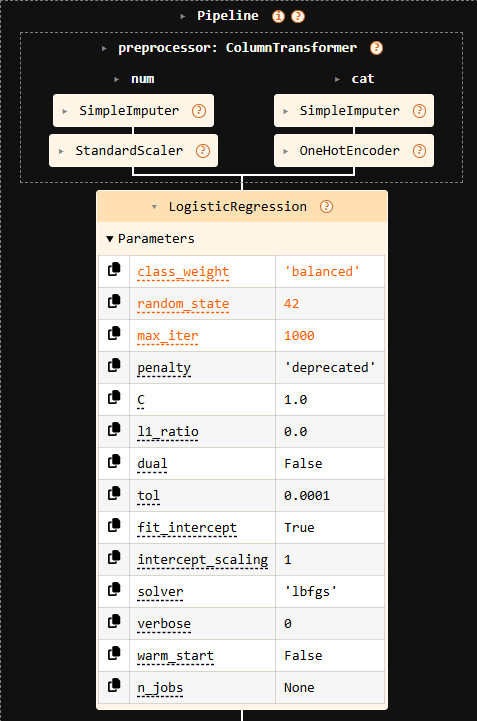

In [239]:
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimator = 300, 
        max_depth = 5, 
        learning_rate = 0.1, 
        scale_pos_weight = scale_weight, 
        random_state = 42,)) 
])

xgb_cv_pipeline

print("Model trained successfully")

Model trained successfully


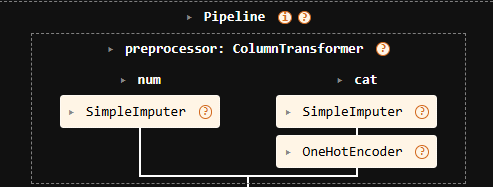

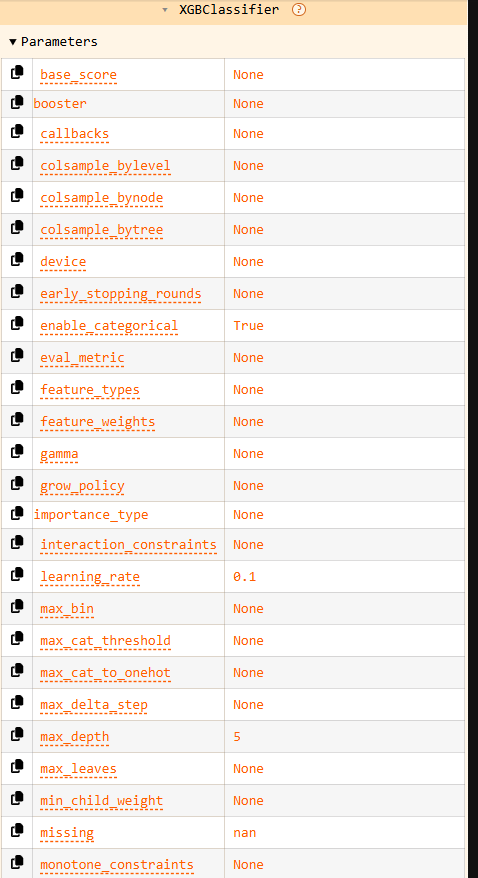

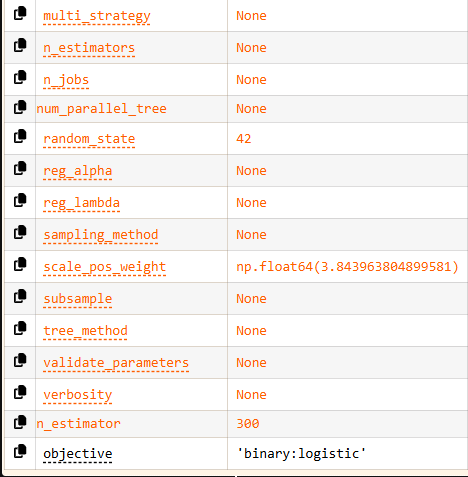

In [216]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),("XGBoost", xgb_cv_pipeline)]:

    cv_results = cross_validate(pipe, X_train , y_train, cv=cv, scoring=scoring, n_jobs=-1)
    print(cv_name)
    print(f"ROC-AUC : {cv_results['test_roc_auc'].mean()}")
    print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
    print(f"Precision : {cv_results['test_precision'].mean()}")
    print(f"Recall : {cv_results['test_recall'].mean()}")
    print(f"F1 : {cv_results['test_f1'].mean()}")
    print()

Logistic Regression
ROC-AUC : 0.8656045014495077
Accuracy : 0.8050851190930318
Precision : 0.5188769829442775
Recall : 0.7746621202275167
F1 : 0.6213921727474645

XGBoost
ROC-AUC : 0.9350084041516924
Accuracy : 0.9016314030053391
Precision : 0.7539981821893701
Recall : 0.777972648349482
F1 : 0.7654809474097533



#### 9. Baseline Model — Logistic Regression
- Start with a simple model first which will be the benchmark to beat.
- Train it and check its score on the test data.

In [240]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight= "balanced"))
])
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully")

Baseline model trained successfully


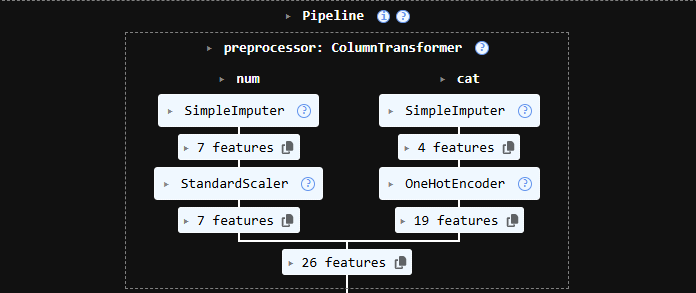

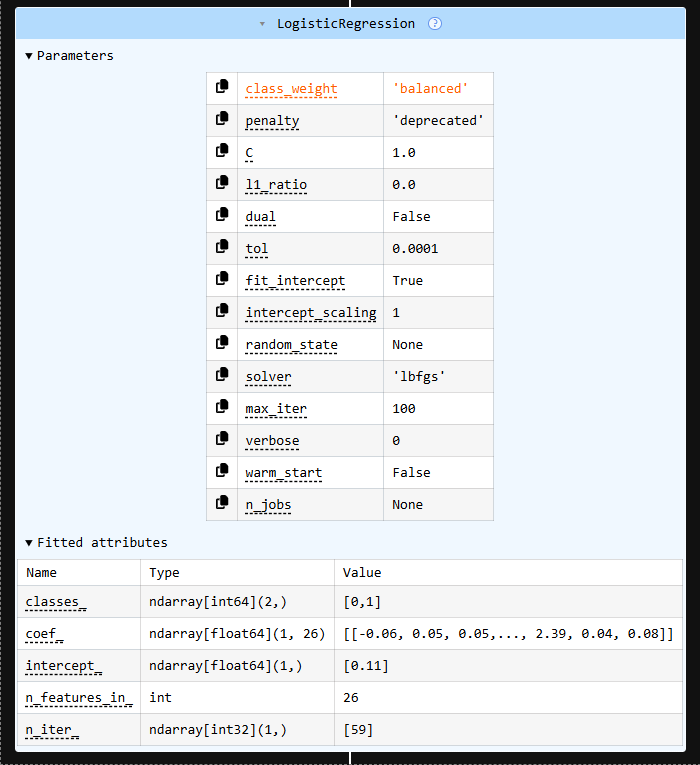

Baseline Logistic Model Metrics:
Accuracy : 0.81
Precision : 0.53
Recall : 0.76
F1 : 0.63

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.87      4355
           1       0.53      0.76      0.63      1133

    accuracy                           0.81      5488
   macro avg       0.73      0.79      0.75      5488
weighted avg       0.85      0.81      0.82      5488



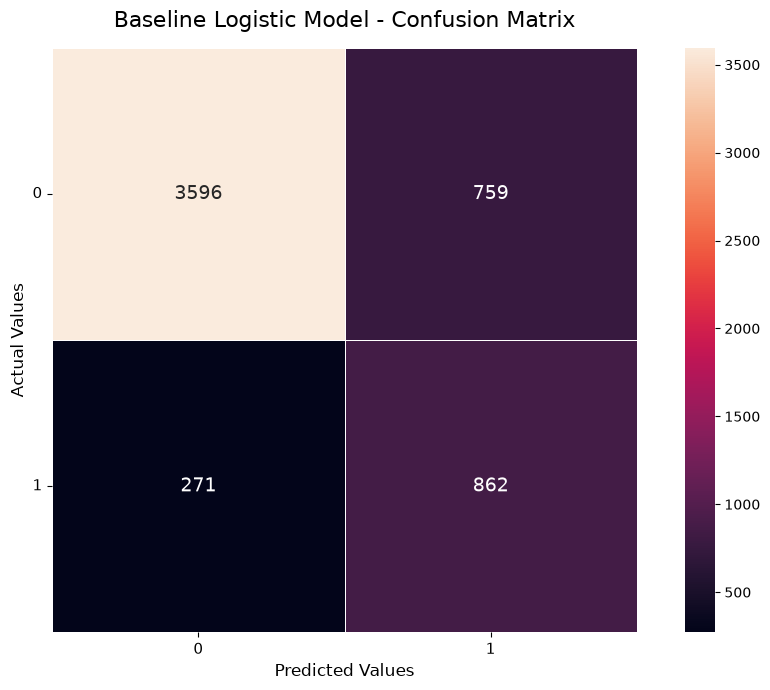

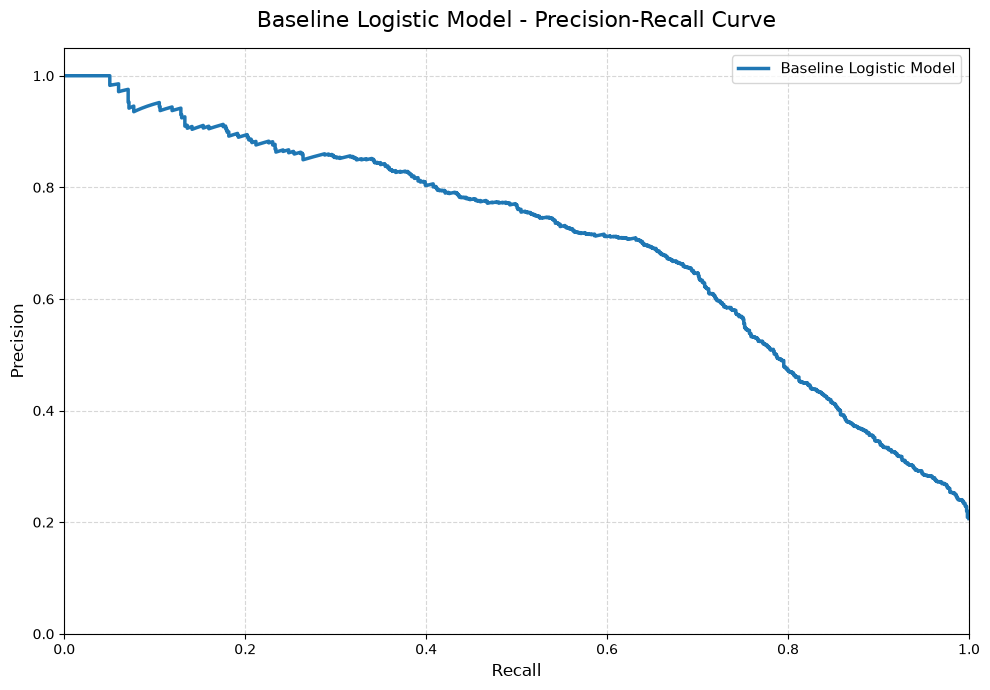

In [218]:
#Evaluate the baseline model

evaluate_model("Baseline Logistic Model", baseline_model, X_test, y_test)

In [241]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg), 
    ('classifier', XGBClassifier(random_state = 42))
])

xg_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

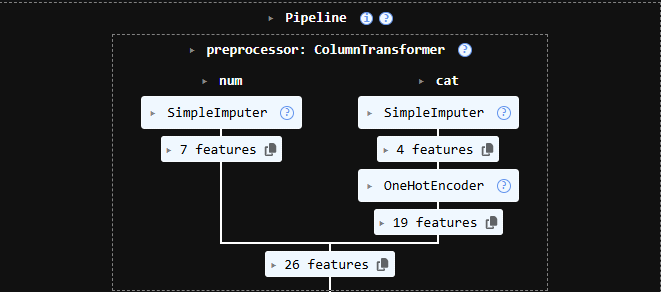

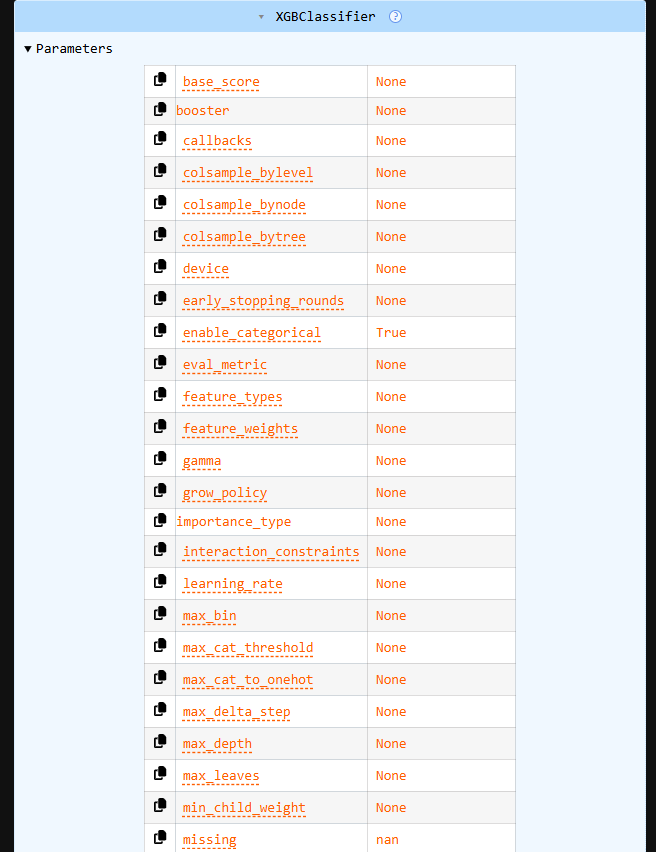

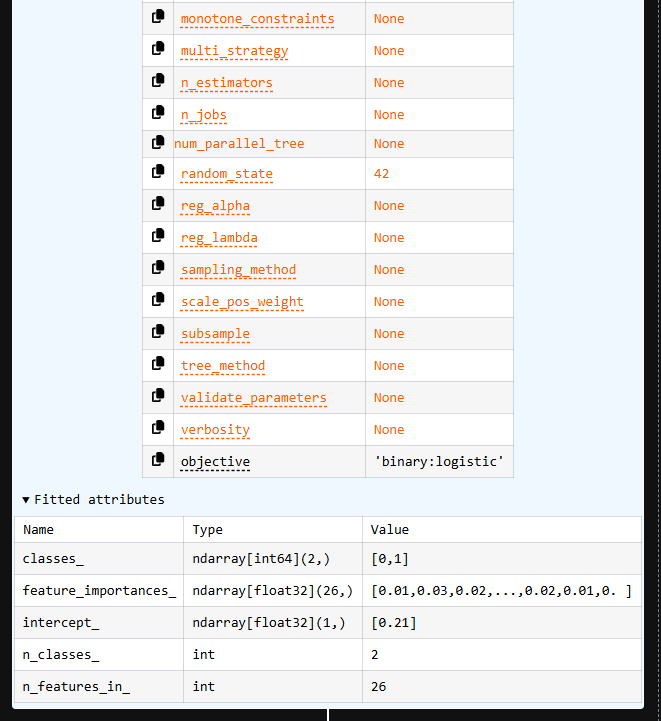

XGB Model Metrics:
Accuracy : 0.93
Precision : 0.97
Recall : 0.71
F1 : 0.82

XGB Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4355
           1       0.97      0.71      0.82      1133

    accuracy                           0.93      5488
   macro avg       0.95      0.85      0.89      5488
weighted avg       0.94      0.93      0.93      5488



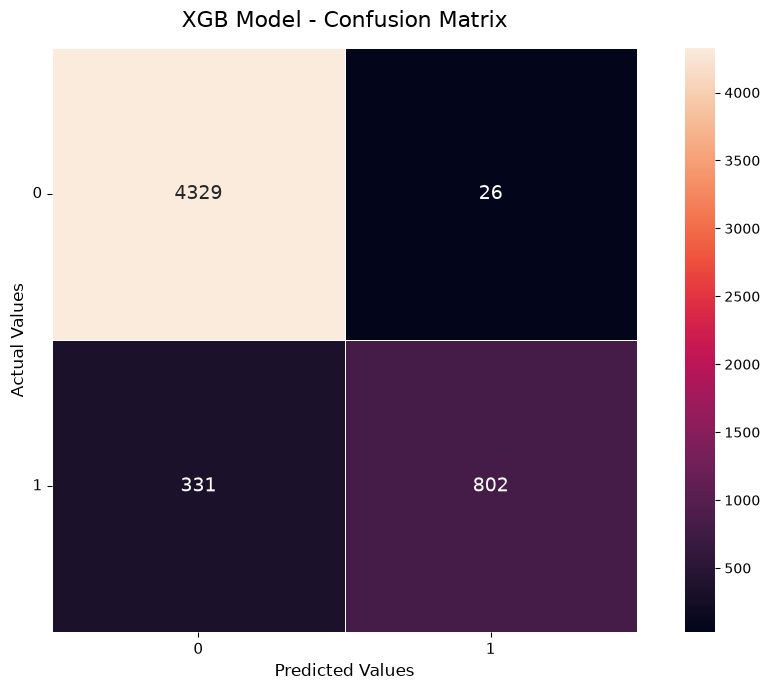

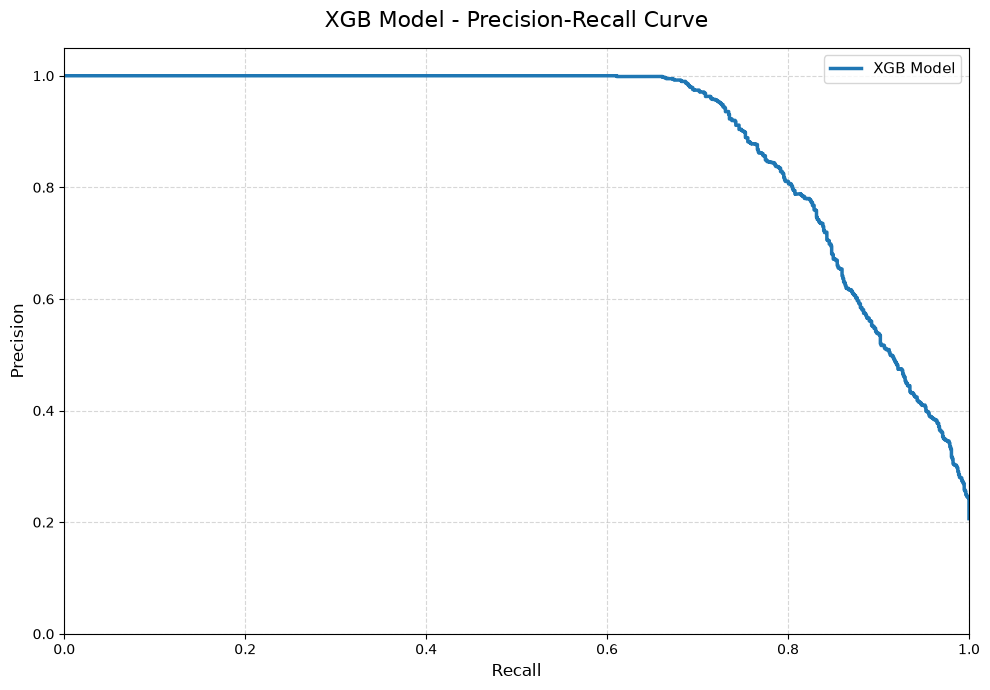

In [220]:
evaluate_model("XGB Model", xg_model, X_test, y_test) # Evaluating before hyperparameter tuning

#### 10. XGBoost Hyperparameter Tuning

- Move to a stronger model, XGBoost.
- A model has many settings called hyperparameters.
- Search for the best combination of these settings.
- Use cross-validation while searching, so the result is reliable.

In [221]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits ->  simpler tree -> low overfitting

In [222]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': <scipy.stats....001C8FD7251C0>, 'classifier__gamma': <scipy.stats....001C8FFAF0620>, 'classifier__learning_rate': <scipy.stats....001C8BB59CC20>, 'classifier__max_depth': <scipy.stats....001C8FF43E5D0>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index

In [223]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

random_search.best_params_

Score after performing Tunning 0.89


{'classifier__colsample_bytree': np.float64(0.810480558728617),
 'classifier__gamma': np.float64(0.8745220196889641),
 'classifier__learning_rate': np.float64(0.09966793675887091),
 'classifier__max_depth': 8,
 'classifier__min_child_weight': 5,
 'classifier__n_estimators': 359,
 'classifier__subsample': np.float64(0.9410046777621399)}

#### 11. Compare Both Models Side by Side

- Compare Logistic Regression and XGBoost.
- Look at their scores together in one table, which will help to pick the better performing model.

In [224]:
# Function to compare the model performance side by side for better understandability
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    average_precision_score
)


def compare_models(
    model1_name, model1,
    model2_name, model2,
    X_test, y_test,
    thresholds=None
):

    # Store model information
    models = {
        model1_name: model1,
        model2_name: model2
    }

    results = {}
    predictions = {}
    probabilities = {}

    # Default thresholds
    if thresholds is None:
        thresholds = {}

    # Evaluate both models
    for model_name, model in models.items():

        # Predicted probabilities
        y_pred_prob = model.predict_proba(X_test)[:, 1]

        # Apply custom threshold if provided
        if model_name in thresholds:
            threshold = thresholds[model_name]
            y_pred = (y_pred_prob >= threshold).astype(int)
        else:
            threshold = None
            y_pred = model.predict(X_test)

        # Store predictions
        predictions[model_name] = y_pred
        probabilities[model_name] = y_pred_prob

        # Calculate metrics
        results[model_name] = {
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1 Score": f1_score(y_test, y_pred, zero_division=0),
            "PR-AUC": average_precision_score(y_test, y_pred_prob)
        }

    
    # 1. Performance Metrics Comparison

    metrics_df = pd.DataFrame(results).T

    print("\n========== MODEL PERFORMANCE COMPARISON ==========\n")
    display(metrics_df.round(4))

    # 2. Classification Reports Side by Side

    reports = {}

    for model_name in models:

        report = classification_report(
            y_test,
            predictions[model_name],
            output_dict=True,
            zero_division=0
        )

        reports[model_name] = pd.DataFrame(report).T

    report_comparison = pd.concat(
        reports,
        axis=1
    )

    print("\n========== CLASSIFICATION REPORT COMPARISON ==========\n")
    display(report_comparison.round(4))

    # 3. Confusion Matrices Side by Side

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for ax, model_name in zip(axes, models):

        conf_matrix = confusion_matrix(
            y_test,
            predictions[model_name],
            labels=[0, 1]
        )

        sns.heatmap(
            conf_matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            linewidths=0.5,
            square=True,
            cbar=False,
            annot_kws={"size": 14},
            ax=ax
        )

        ax.set_title(f"{model_name} Confusion Matrix", fontsize=14, pad=12)
        ax.set_xlabel("Predicted Values", fontsize=12)
        ax.set_ylabel("Actual Values", fontsize=12)
        ax.set_xticklabels(["Non-default", "Default"])
        ax.set_yticklabels(["Non-default", "Default"], rotation=0)

    plt.tight_layout()
    plt.show()

    # 4. Precision-Recall Curve Comparison

    plt.figure(figsize=(11, 7))

    for model_name in models:

        precisions, recalls, _ = precision_recall_curve(
            y_test,
            probabilities[model_name]
        )

        pr_auc = results[model_name]["PR-AUC"]

        plt.plot(
            recalls,
            precisions,
            linewidth=2.5,
            label=f"{model_name} (AP = {pr_auc:.4f})"
        )

    plt.xlabel("Recall", fontsize=12)
    plt.ylabel("Precision", fontsize=12)
    plt.title("Precision-Recall Curve Comparison", fontsize=15, pad=15)

    plt.xlim(0, 1)
    plt.ylim(0, 1.05)

    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(fontsize=11)

    plt.tight_layout()
    plt.show()

    return metrics_df, report_comparison


========== MODEL PERFORMANCE COMPARISON ==========



,Accuracy,Precision,Recall,F1 Score,PR-AUC
Logistic Regression,0.8123,0.5318,0.7608,0.6260,0.7058
XGBoost Model,0.9357,0.9733,0.7079,0.8196,0.9016



========== CLASSIFICATION REPORT COMPARISON ==========



Logistic Regression                             XGBoost Model  \
                       precision  recall f1-score    support     precision   
0                         0.9299  0.8257   0.8747  4355.0000        0.9290   
1                         0.5318  0.7608   0.6260  1133.0000        0.9733   
accuracy                  0.8123  0.8123   0.8123     0.8123        0.9357   
macro avg                 0.7308  0.7933   0.7504  5488.0000        0.9512   
weighted avg              0.8477  0.8123   0.8234  5488.0000        0.9382   

                                          
              recall f1-score    support  
0             0.9949   0.9609  4355.0000  
1             0.7079   0.8196  1133.0000  
accuracy      0.9357   0.9357     0.9357  
macro avg     0.8514   0.8902  5488.0000  
weighted avg  0.9357   0.9317  5488.0000

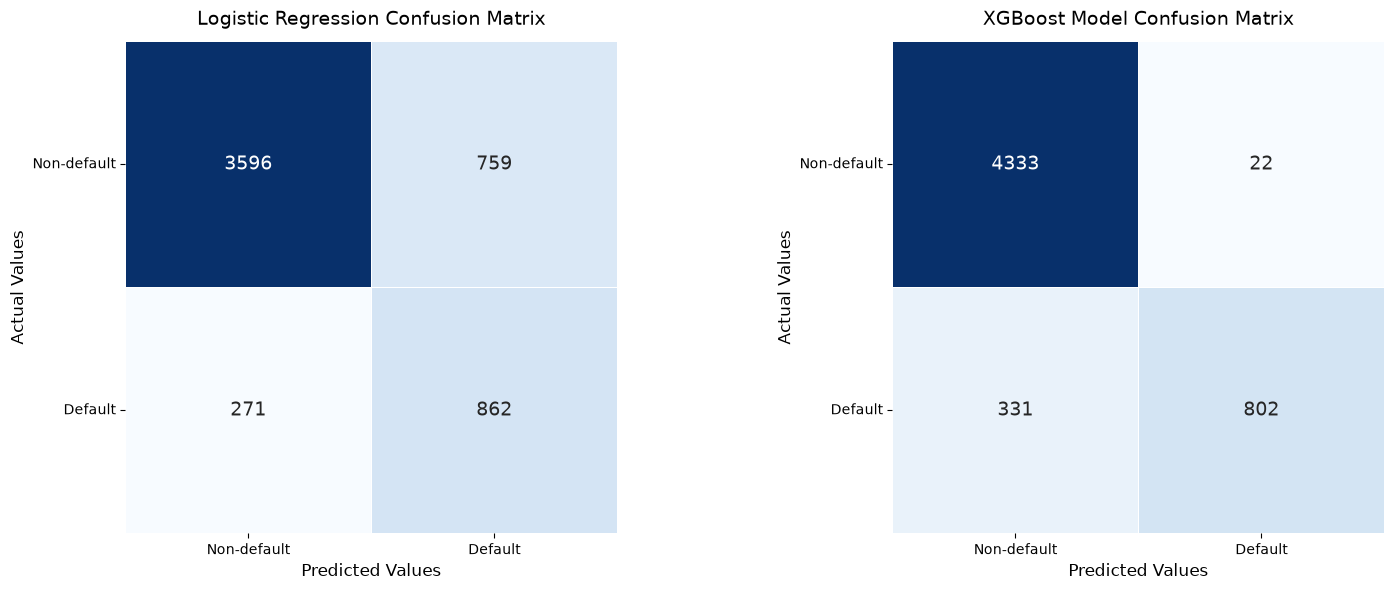

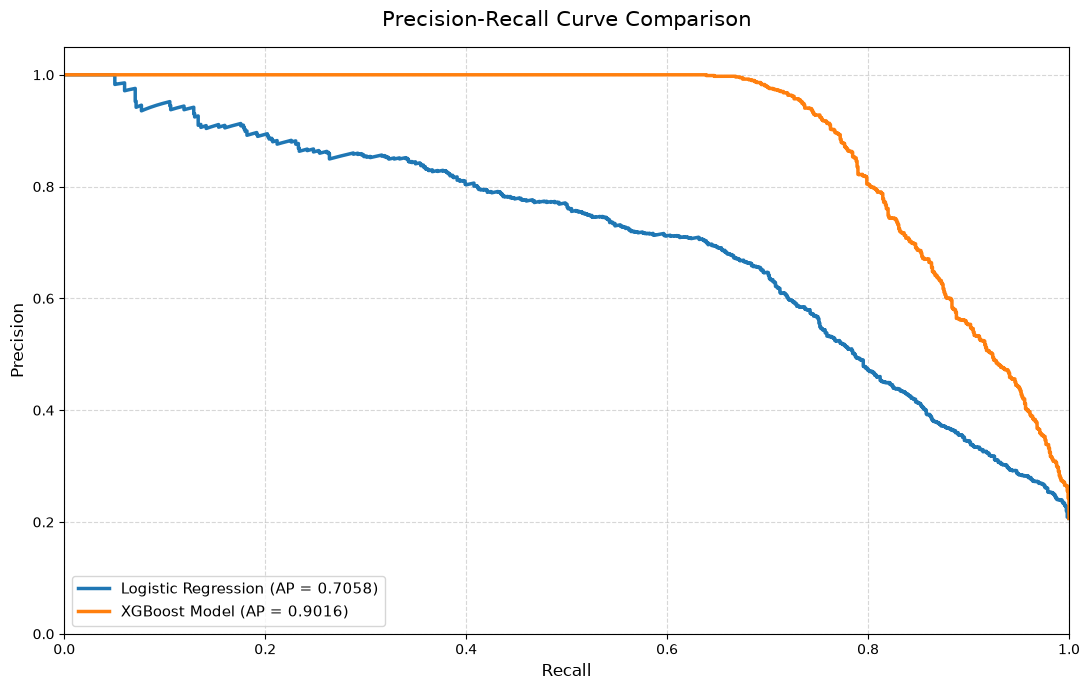

In [225]:
metrics, reports = compare_models(
    "Logistic Regression", baseline_model,
    "XGBoost Model", random_search,
    X_test,
    y_test
)

#### Precision-Recall Curve Comparison – Model Evaluation

Based on the Precision-Recall curve comparison, **XGBoost outperforms Logistic Regression** in terms of overall precision-recall performance. XGBoost achieves an Average Precision (AP) score of **0.9010**, whereas Logistic Regression achieves **0.7058**. The XGBoost curve consistently maintains higher precision across almost the entire recall range, indicating its stronger ability to identify positive-class observations while maintaining fewer false positives at comparable recall levels. This suggests that XGBoost captures the underlying patterns in the dataset more effectively than Logistic Regression, particularly when identifying potential loan defaulters. Therefore, XGBoost demonstrates better performance for this classification task based on the Precision-Recall evaluation. However, the final model selection should also consider other evaluation metrics, classification thresholds, probability calibration, and the business costs associated with false positives and false negatives.

#### 12. Optimizing the Classification Threshold

- The model gives a probability, not a direct yes or no.
- Decide a cut-off point to turn it into a decision.
- Check different cut-off points and pick the best one.

Optimal Threshold: 0.4328
Best F1-Score: 0.8238
XGBoost Metrics:
Used Threshold : 0.43
Accuracy : 0.94
Precision : 0.95
Recall : 0.73
F1 : 0.82

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4355
           1       0.95      0.73      0.82      1133

    accuracy                           0.94      5488
   macro avg       0.94      0.86      0.89      5488
weighted avg       0.94      0.94      0.93      5488



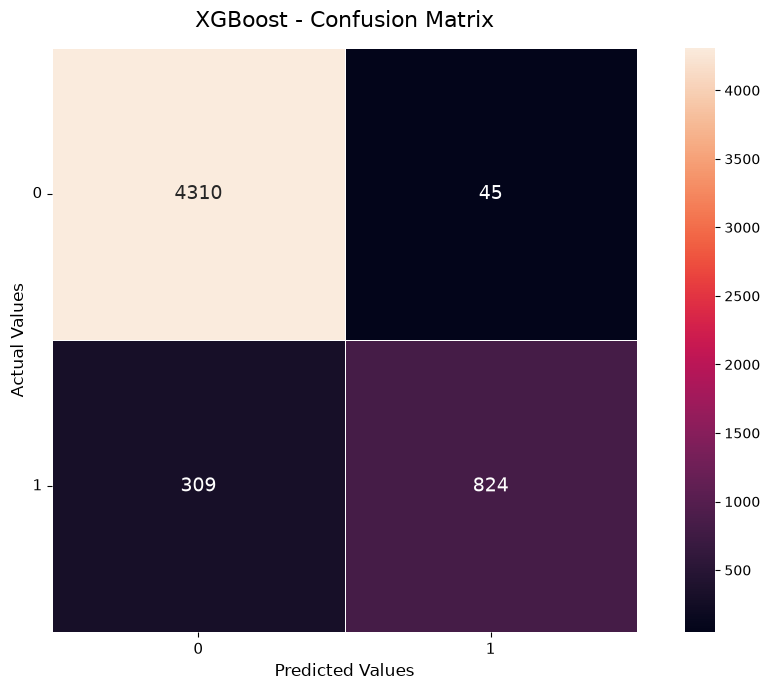

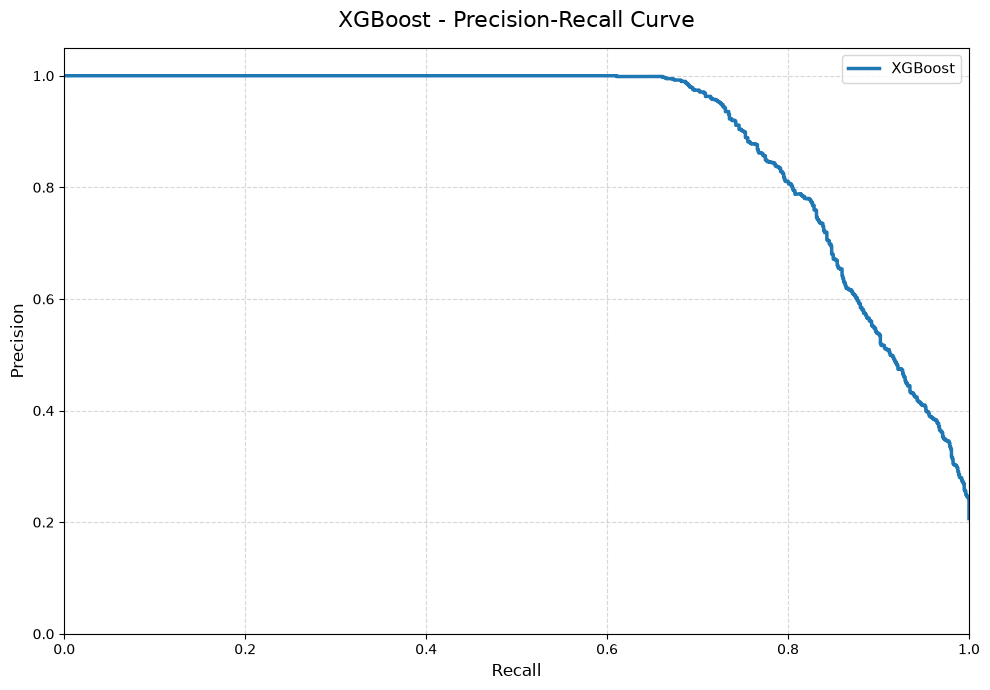

In [226]:
# Get the probability of positive class (Default = 1)
prob = xg_model.predict_proba(X_test)[:, 1]

# Calculate Precision, Recall and Thresholds
precisions, recalls, thresholds = precision_recall_curve(
    y_test,
    prob
)

# Calculate F1-score for each threshold
f1_scores = (
    2 * (precisions[:-1] * recalls[:-1]) /
    (precisions[:-1] + recalls[:-1] + 1e-9)
)

# Identify the threshold that produces the highest F1-score
best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Optimal Threshold: {best_threshold:.4f}")
print(f"Best F1-Score: {best_f1:.4f}")

# Evaluate XGBoost using the optimal threshold
evaluate_model(
    "XGBoost",
    xg_model,
    X_test,
    y_test,
    threshold=best_threshold
)

#### 13. Probability Calibration
- Sometimes a model's probability doesn't mean what it says.
- For example, 30% risk should truly mean a 30% chance.
- Check this with a calibration plot.
- Fix it if the probabilities are off.

##### Methods by which we can fix the poorly calibrated model.
1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)
3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature


In [243]:
# Calibrated XGBoost model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)

print("Model calibrated initiated")

Model calibrated initiated


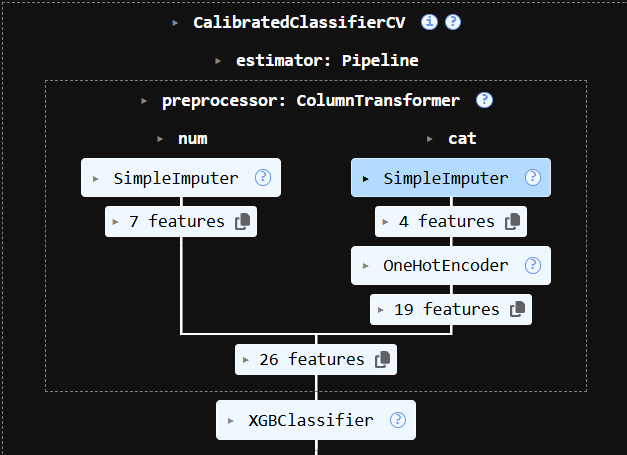

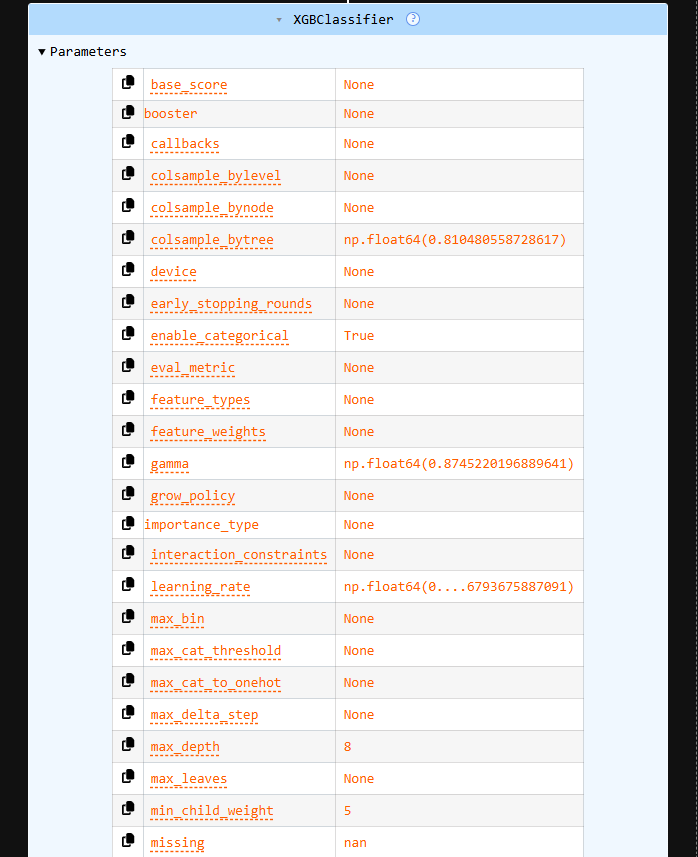

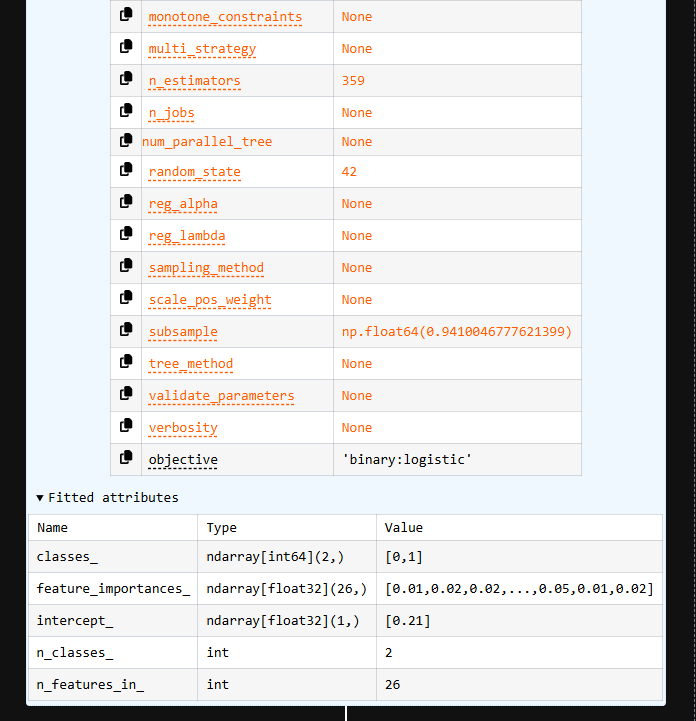

In [244]:
# Get probabilites
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [245]:
# Create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)

In [246]:
actual_cal, predicted_cal  = calibration_curve(y_test, calibrated, n_bins=10)

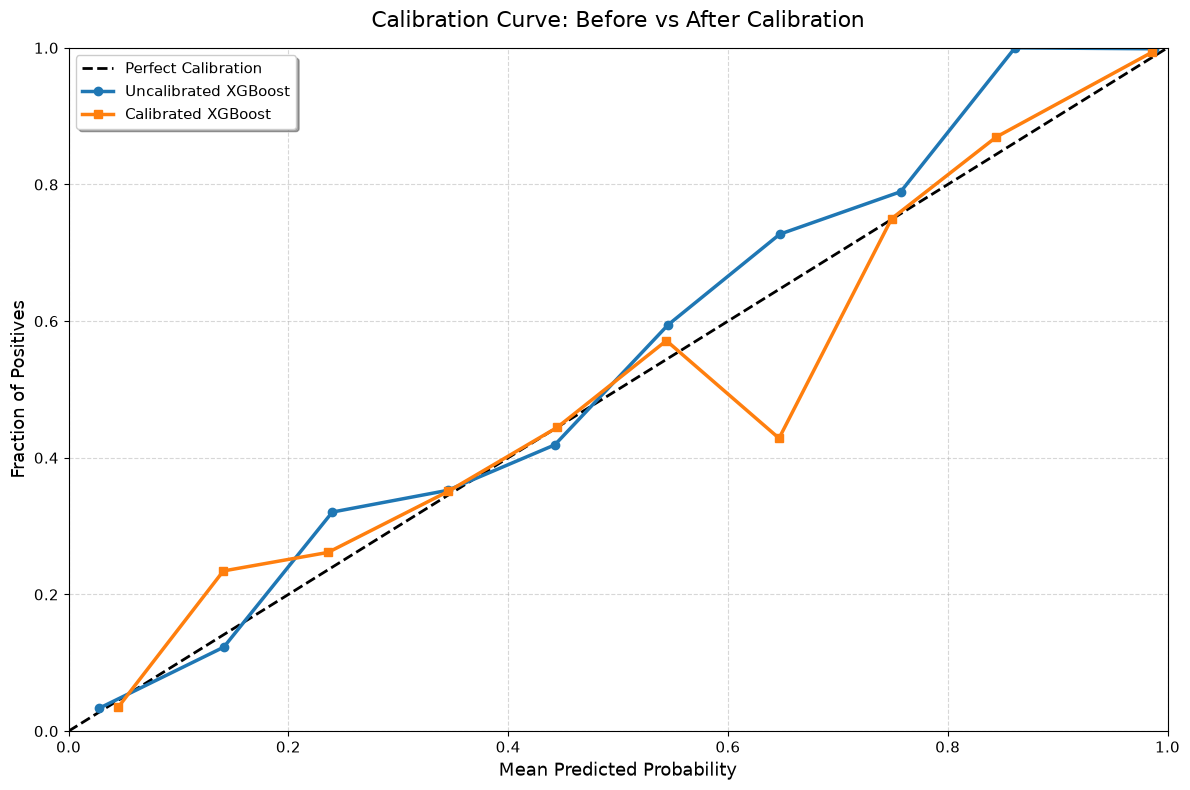

In [248]:
# Plot calibration curves
plt.figure(figsize=(12, 8))

# Perfect calibration reference line
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    linewidth=2,
    label="Perfect Calibration"
)

# Uncalibrated model
plt.plot(
    predicted_uncal,
    actual_uncal,
    marker="o",
    linestyle="-",
    linewidth=2.5,
    markersize=6,
    label="Uncalibrated XGBoost"
)

# Calibrated model
plt.plot(
    predicted_cal,
    actual_cal,
    marker="s",
    linestyle="-",
    linewidth=2.5,
    markersize=6,
    label="Calibrated XGBoost"
)

# Plot formatting
plt.title("Calibration Curve: Before vs After Calibration",
          fontsize=16, pad=15)

plt.xlabel("Mean Predicted Probability", fontsize=13)
plt.ylabel("Fraction of Positives", fontsize=13)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.grid(True, linestyle="--", alpha=0.5)

plt.legend(
    fontsize=11,
    loc="upper left",
    frameon=True,
    shadow=True
)

plt.tight_layout()
plt.show()